In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

torch.manual_seed(42)

In [ ]:
# Load dataset
iris = load_iris()
X, y = iris.data, iris.target

# Split before scaling to prevent data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert to PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Training:", X_train.shape, y_train.shape)
print("Testing:", X_test.shape, y_test.shape)
print("Classes:", iris.target_names)

Training: torch.Size([120, 4]) torch.Size([120])
Testing: torch.Size([30, 4]) torch.Size([30])
Classes: ['setosa' 'versicolor' 'virginica']


In [ ]:
class MLP(nn.Module):
    def __init__(self, input_size=4, hidden_size=16, num_classes=3):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, num_classes)
        )

    def forward(self, x):
        return self.network(x)


In [ ]:
# Fix optimizer import and make sure model/data are on the same device
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
X_train = X_train.to(device)
y_train = y_train.to(device)
X_test = X_test.to(device)
y_test = y_test.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

print("Model device:", next(model.parameters()).device)
print("Train tensors device:", X_train.device, y_train.device)

Model device: cuda:0
Train tensors device: cuda:0 cuda:0


In [ ]:
print(model)

total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params}")

MLP(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=3, bias=True)
  )
)
Total parameters: 403


In [ ]:
epochs = 200
loss_history = []

for epoch in range(epochs):
    model.train()

    optimizer.zero_grad()

    outputs = model(X_train)
    loss = criterion(outputs, y_train)

    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 20 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")

Epoch [20/200], Loss: 0.0002
Epoch [40/200], Loss: 0.0001
Epoch [60/200], Loss: 0.0000
Epoch [80/200], Loss: 0.0000
Epoch [100/200], Loss: 0.0000
Epoch [120/200], Loss: 0.0000
Epoch [140/200], Loss: 0.0000
Epoch [160/200], Loss: 0.0000
Epoch [180/200], Loss: 0.0000
Epoch [200/200], Loss: 0.0000


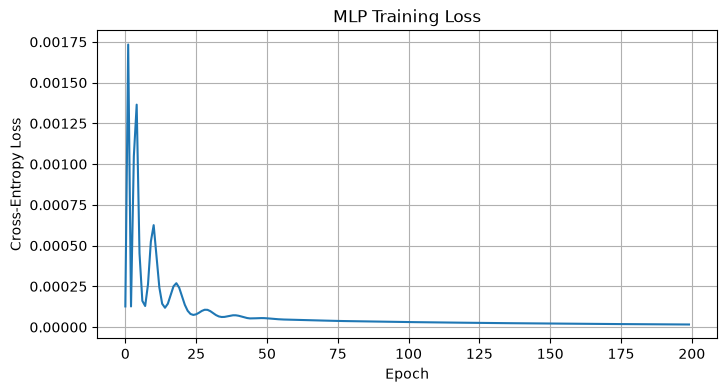

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("MLP Training Loss")
plt.grid(True)
plt.show()

In [ ]:
model.eval()

with torch.no_grad():
    test_outputs = model(X_test)
    _, predicted = torch.max(test_outputs, 1)

accuracy = accuracy_score(y_test.cpu(), predicted.cpu())
print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 96.67%


In [ ]:
sample = X_test[0:1]

model.eval()
with torch.no_grad():
    logits = model(sample)
    probabilities = torch.softmax(logits, dim=1)
    predicted_class = probabilities.argmax(dim=1).item()

print("Predicted:", iris.target_names[predicted_class])
print("Actual:", iris.target_names[y_test[0].item()])
print("Probabilities:", probabilities[0].tolist())

Predicted: setosa
Actual: setosa
Probabilities: [1.0, 5.105883371708992e-16, 1.536536824560614e-15]
